In [ ]:
from pathlib import Path
import yaml

data_yaml = Path(r"C:\Users\User\OneDrive\Desktop\RoadVision AI\Datasets\RoadScan_Final\data.yaml")

with open(data_yaml, "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

print(data)

root = Path(data["path"])

for split in ["train", "val", "test"]:
    img_dir = root / "images" / split
    lbl_dir = root / "labels" / split

    image_count = len([
        p for p in img_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    label_count = len(list(lbl_dir.glob("*.txt")))

    print(split, image_count, label_count)

    assert image_count == label_count

In [3]:
root = Path(data["path"])

for split in ["train", "val", "test"]:
    img_dir = root / "images" / split
    lbl_dir = root / "labels" / split

    image_count = len([
        p for p in img_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    label_count = len(list(lbl_dir.glob("*.txt")))

    print(split, image_count, label_count)

    assert image_count == label_count

train 27336 27336
val 5849 5849
test 5855 5855


In [2]:
from pathlib import Path
import yaml

data_yaml = Path.cwd() / "data.yaml"

with open(data_yaml, "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

print(data["path"])

C:/RoadScan/RoadScan_Final


In [4]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

PyTorch: 2.14.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM GB: 8.0


In [5]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

model.train(
    data=r"C:\RoadScan\RoadScan_Final\data.yaml",
    epochs=1,
    imgsz=640,
    batch=8,
    device=0,
    workers=0,
    fraction=0.05,
    name="roadscan_smoke_test"
)

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\User\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.203  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\RoadScan\RoadScan_Final\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, fl

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001F0C5C27AD0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
    

In [6]:
from pathlib import Path

weights = Path("runs/detect/roadscan_smoke_test/weights")

print("Best model:", (weights / "best.pt").exists())
print("Last model:", (weights / "last.pt").exists())

Best model: True
Last model: True


In [8]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("YOLO11s downloaded and loaded successfully!")

YOLO11s downloaded and loaded successfully!


In [9]:
from pathlib import Path

weights = Path.cwd() / "yolo11s.pt"

print("Model exists:", weights.exists())

Model exists: True


In [10]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path.cwd() / "yolo11s.pt"

assert model_path.exists(), "YOLO11s weights missing!"

model = YOLO(str(model_path))

model.train(
    data=r"C:\RoadScan\RoadScan_Final\data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    workers=0,
    patience=15,
    cache=False,
    project=r"C:\RoadScan\runs",
    name="roadscan_yolo11s_50epochs"
)

Ultralytics 8.4.203  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\RoadScan\RoadScan_Final\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=c:\Users\User\OneDrive\Desktop\RoadVision AI\yolo11s.pt, momentum=0.937, mosaic=1.0, multi_

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001F0C6257920>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
    

In [11]:
from pathlib import Path
from ultralytics import YOLO

# Your completed YOLO11s training run
run_dir = Path(
    r"C:\RoadScan\runs\roadscan_yolo11s_50epochs"
)

best_model = run_dir / "weights" / "best.pt"

assert best_model.exists(), "Trained model not found!"

model = YOLO(str(best_model))

# Re-evaluate on the validation dataset
metrics = model.val(
    data=r"C:\RoadScan\RoadScan_Final\data.yaml",
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    workers=0,
    plots=True,
    project=r"C:\RoadScan\runs",
    name="yolo11s_validation_check"
)

print("\n--- Verified validation metrics ---")
print(f"Precision:  {metrics.box.mp:.4f}")
print(f"Recall:     {metrics.box.mr:.4f}")
print(f"mAP50:      {metrics.box.map50:.4f}")
print(f"mAP50-95:   {metrics.box.map:.4f}")
print("Results directory:", metrics.save_dir)

Ultralytics 8.4.203  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 41.2±49.4 MB/s, size: 479.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\User\OneDrive\Desktop\RoadVision AI\Datasets\RoadScan_Final\labels\val.cache... 5849 images, 2265 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5849/5849  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 732/732 3.5it/s 3:290.2ss
                   all       5849       8366      0.655      0.559      0.604      0.328
    Longitudinal Crack       2011       3890       0.62      0.526      0.564      0.316
      Transverse Crack       1158       1769      0.605      0.525      0.549      

In [12]:
from pathlib import Path
import yaml

yaml_path = Path(r"C:\RoadScan\RoadScan_Final\data.yaml")

data = yaml.safe_load(yaml_path.read_text(encoding="utf-8"))

print("Dataset root:", data["path"])
print("Validation:", data["val"])

Dataset root: c:/Users/User/OneDrive/Desktop/RoadVision AI/Datasets/RoadScan_Final
Validation: images/val


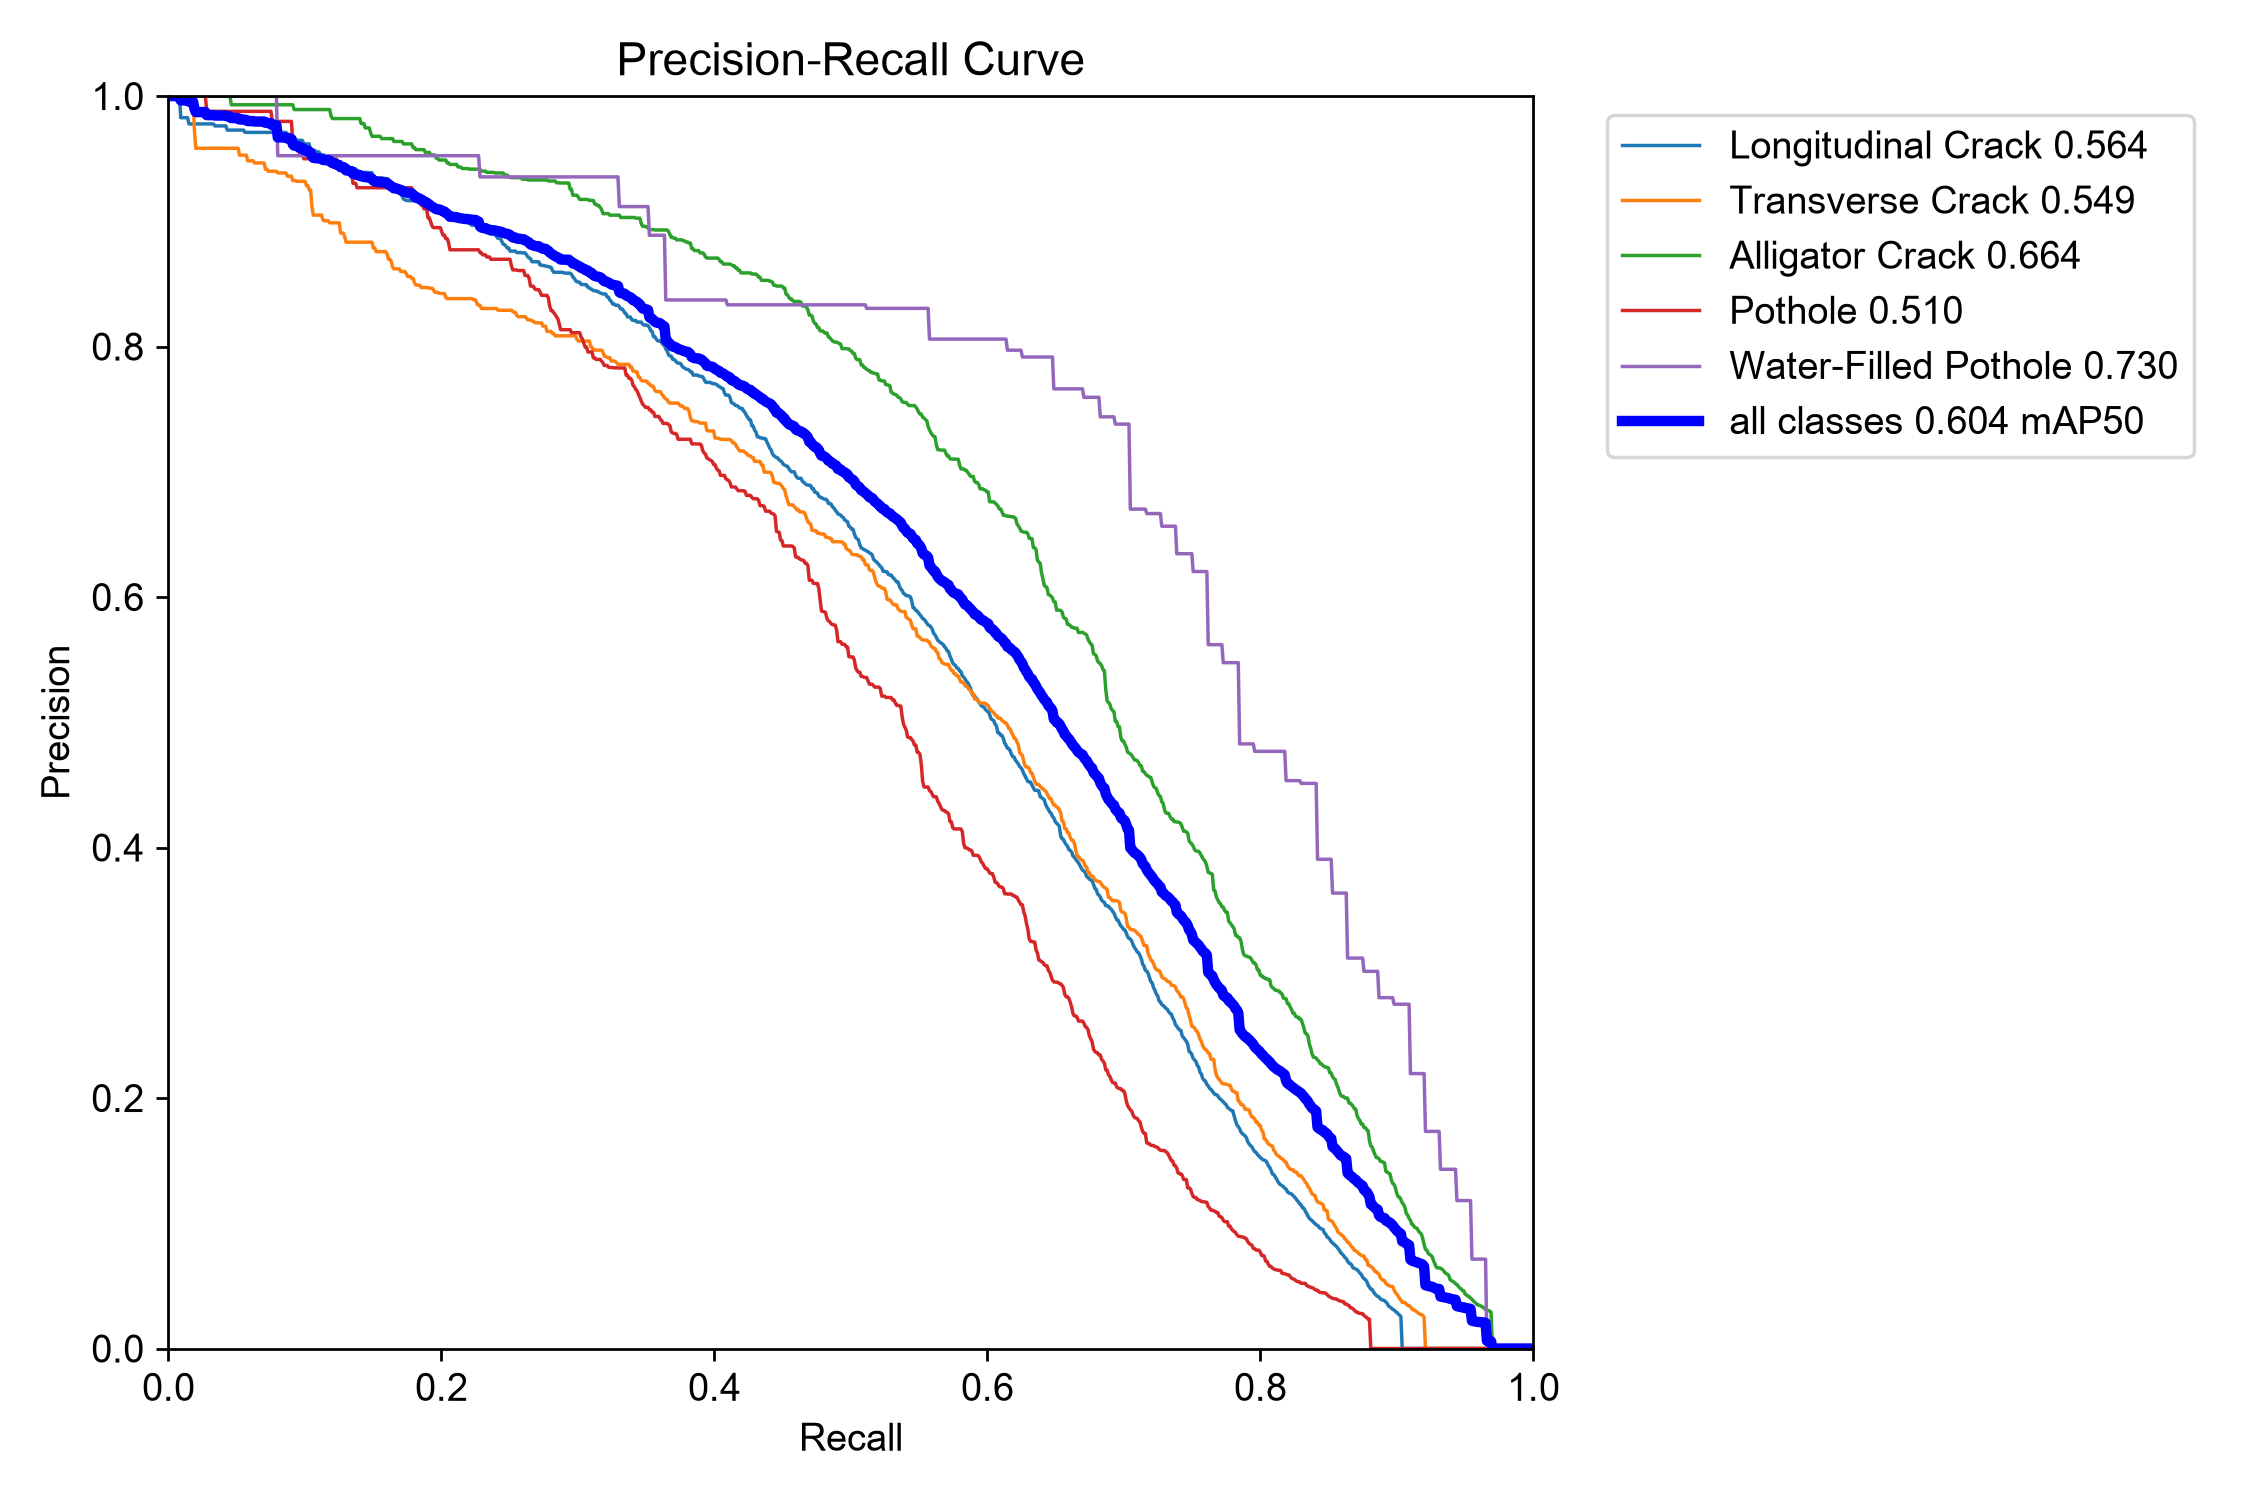

In [13]:
from pathlib import Path
from IPython.display import Image, display

folder = Path(r"C:\RoadScan\runs\yolo11s_validation_check")

display(Image(filename=str(folder / "BoxPR_curve.png")))